# Daily Electricity Demand Prediction Using XGBoost

## Objective
Build a simple machine learning model to predict daily electricity demand using historical electricity consumption data.

## Algorithm
XGBoost Regressor

## Problem Type
Regression / Time-Series Forecasting

## Workflow
1. Dataset Inspection
2. Data Preprocessing
3. Exploratory Data Analysis
4. Feature Engineering
5. Model Training
6. Model Evaluation
7. Feature Importance

In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

# Dataset location
DATA_PATH = Path("../data/raw")

# Find CSV files
csv_files = list(DATA_PATH.glob("*.csv"))

print("Available CSV files:")
for file in csv_files:
    print(file.name)

# Load dataset
if not csv_files:
    raise FileNotFoundError("No CSV file found inside data/raw/")

df = pd.read_csv(csv_files[0])

# Dataset inspection
print("\nDataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

print("\nXGBoost version:", xgb.__version__)
print("\nDataset inspection completed.")

Available CSV files:
electricity.csv

Dataset shape: (45312, 9)

First five records:


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,b'2',0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,b'UP'
1,0.0,b'2',0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,b'UP'
2,0.0,b'2',0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,b'UP'
3,0.0,b'2',0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,b'UP'
4,0.0,b'2',0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,b'DOWN'



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45312 entries, 0 to 45311
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       45312 non-null  float64
 1   day        45312 non-null  object 
 2   period     45312 non-null  float64
 3   nswprice   45312 non-null  float64
 4   nswdemand  45312 non-null  float64
 5   vicprice   45312 non-null  float64
 6   vicdemand  45312 non-null  float64
 7   transfer   45312 non-null  float64
 8   class      45312 non-null  object 
dtypes: float64(7), object(2)
memory usage: 3.1+ MB

Missing values:


date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64


Statistical summary:


,date,period,nswprice,nswdemand,vicprice,vicdemand,transfer
count,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000,45312.000000
mean,0.499080,0.500000,0.057868,0.425418,0.003467,0.422915,0.500526
std,0.340308,0.294756,0.039991,0.163323,0.010213,0.120965,0.153373
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.031934,0.250000,0.035127,0.309134,0.002277,0.372346,0.414912
50%,0.456329,0.500000,0.048652,0.443693,0.003467,0.422915,0.414912
75%,0.880547,0.750000,0.074336,0.536001,0.003467,0.469252,0.605702
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000



XGBoost version: 3.2.0

Dataset inspection completed.


In [2]:
# Inspect temporal structure

print("Unique dates:", df["date"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())

print("\nUnique day values:")
print(df["day"].unique())

print("\nPeriod range:")
print(df["period"].min(), "to", df["period"].max())

print("\nNumber of unique periods:")
print(df["period"].nunique())

print("\nRecords per date:")
print(df.groupby("date").size().describe())

print("\nFirst and last records:")
display(df[["date", "day", "period"]].head(10))
display(df[["date", "day", "period"]].tail(10))

print("\nDemand statistics:")
display(df[["nswdemand", "vicdemand"]].describe())

print("\nClass distribution:")
display(df["class"].value_counts())

Unique dates: 933
Date range: 0.0 to 1.0

Unique day values:
["b'2'" "b'3'" "b'4'" "b'5'" "b'6'" "b'7'" "b'1'"]

Period range:
0.0 to 1.0

Number of unique periods:
48

Records per date:
count    933.000000
mean      48.565916
std        5.183872
min       48.000000
25%       48.000000
50%       48.000000
75%       48.000000
max       96.000000
dtype: float64

First and last records:


,date,day,period
0,0.0,b'2',0.000000
1,0.0,b'2',0.021277
2,0.0,b'2',0.042553
3,0.0,b'2',0.063830
4,0.0,b'2',0.085106
5,0.0,b'2',0.106383
6,0.0,b'2',0.127660
7,0.0,b'2',0.148936
8,0.0,b'2',0.170213
9,0.0,b'2',0.191489


,date,day,period
45302,0.9158,b'7',0.808511
45303,0.9158,b'7',0.829787
45304,0.9158,b'7',0.851064
45305,0.9158,b'7',0.872340
45306,0.9158,b'7',0.893617
45307,0.9158,b'7',0.914894
45308,0.9158,b'7',0.936170
45309,0.9158,b'7',0.957447
45310,0.9158,b'7',0.978723
45311,0.9158,b'7',1.000000



Demand statistics:


,nswdemand,vicdemand
count,45312.000000,45312.000000
mean,0.425418,0.422915
std,0.163323,0.120965
min,0.000000,0.000000
25%,0.309134,0.372346
50%,0.443693,0.422915
75%,0.536001,0.469252
max,1.000000,1.000000



Class distribution:


class
b'DOWN'    26075
b'UP'      19237
Name: count, dtype: int64

In [3]:
with open("dataset_report.txt", "w") as f:
    f.write(f"Shape: {df.shape}\n")
    f.write(f"Unique dates: {df['date'].nunique()}\n")
    f.write(f"Date range: {df['date'].min()} to {df['date'].max()}\n")
    f.write(f"Days: {df['day'].unique()}\n")
    f.write(f"Periods: {df['period'].nunique()}\n")
    f.write("\nRecords per date:\n")
    f.write(df.groupby("date").size().describe().to_string())
    f.write("\n\nDemand statistics:\n")
    f.write(df[["nswdemand", "vicdemand"]].describe().to_string())
    f.write("\n\nClass distribution:\n")
    f.write(df["class"].value_counts().to_string())

print("Report saved!")

Report saved!


Model training completed!
Training observations: 740
Testing observations: 186


,Actual Demand,Predicted Demand
0,0.378787,0.428860
1,0.358661,0.341102
2,0.392443,0.445663
3,0.524447,0.461529
4,0.531662,0.505676
5,0.523012,0.495374
6,0.508095,0.491642
7,0.432129,0.421916
8,0.366502,0.344615
9,0.548135,0.390078


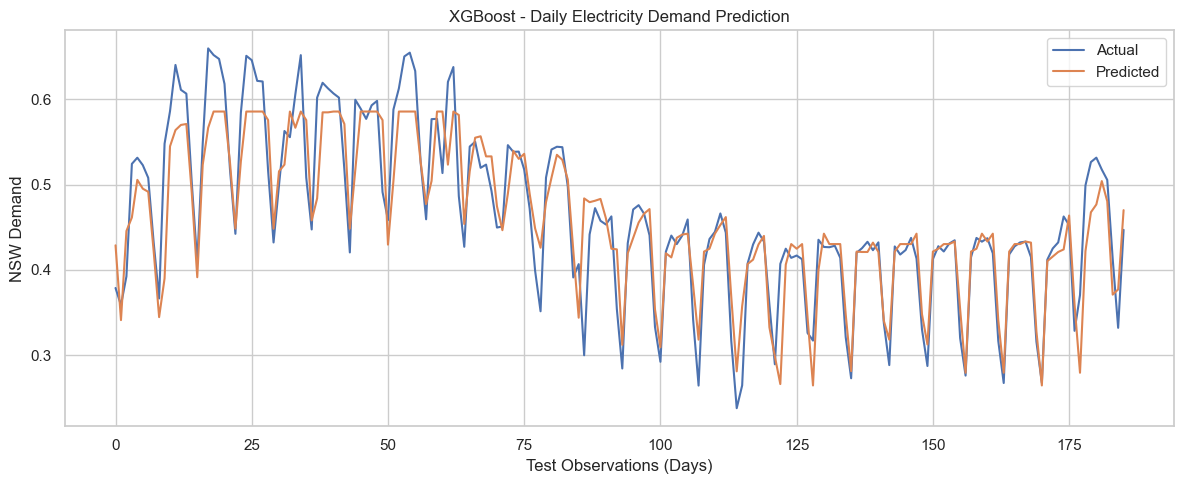

In [4]:
# Daily aggregation
daily_df = df.groupby("date", as_index=False).agg({
    "nswdemand": "mean"
})

# Feature engineering
daily_df["lag_1"] = daily_df["nswdemand"].shift(1)
daily_df["lag_7"] = daily_df["nswdemand"].shift(7)

daily_df["rolling_mean_7"] = (
    daily_df["nswdemand"].shift(1).rolling(7).mean()
)

# Remove rows with missing lag values
daily_df = daily_df.dropna()

# Features and target
X = daily_df[["lag_1", "lag_7", "rolling_mean_7"]]
y = daily_df["nswdemand"]

# Chronological 80/20 split
split = int(len(daily_df) * 0.8)

X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Train XGBoost
model = xgb.XGBRegressor(
    n_estimators=50,
    max_depth=3,
    learning_rate=0.1,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=2,
    random_state=42
)

model.fit(X_train, y_train)

# Generate predictions
predictions = model.predict(X_test)

print("Model training completed!")
print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Display predictions
results = pd.DataFrame({
    "Actual Demand": y_test.values,
    "Predicted Demand": predictions
})

display(results.head(15))

# Plot predictions
plt.figure(figsize=(12, 5))
plt.plot(results["Actual Demand"].values, label="Actual")
plt.plot(results["Predicted Demand"].values, label="Predicted")
plt.title("XGBoost - Daily Electricity Demand Prediction")
plt.xlabel("Test Observations (Days)")
plt.ylabel("NSW Demand")
plt.legend()
plt.tight_layout()
plt.show()